```markdown
# Project: Emotion Classification and Sentiment Analysis of Social Media Text

This project implements a comprehensive machine learning pipeline that uses:
1. **Unsupervised/Lexicon Sentiment Scoring**: VADER Sentiment Analysis and Dictionary-Based Scoring to generate continuous and categorical sentiment features.
2. **Supervised Classifier Models**: Logistic Regression, Support Vector Machine (SVM), and Multinomial Naive Bayes to classify the text into 6 target emotion classes:
   - 0: Sadness
   - 1: Joy
   - 2: Love
   - 3: Anger
   - 4: Fear
   - 5: Surprise
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

nltk.download('vader_lexicon')

# Load the dataset
file_path = '/content/DataSet - Complete.csv'
df = pd.read_csv(file_path)

# Display data shape and info
print(f"Dataset Shape: {df.shape}")
display(df.info())
display(df.head())

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Dataset Shape: (19999, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19999 entries, 0 to 19998
Data columns (total 3 columns):
 #   Column                                         Non-Null Count  Dtype 
---  ------                                         --------------  ----- 
 0   0                                              19999 non-null  int64 
 1   i just feel really helpless and heavy hearted  19999 non-null  object
 2   4                                              19999 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 468.9+ KB


None

,0,i just feel really helpless and heavy hearted,4
0,1,ive enjoyed being able to slouch about relax a...,0
1,2,i gave up my internship with the dmrg and am f...,4
2,3,i dont know i feel so lost,0
3,4,i am a kindergarten teacher and i am thoroughl...,4
4,5,i was beginning to feel quite disheartened,0


```markdown
## Exploratory Data Analysis & Visualizations
Let's analyze the distribution of the target emotion label to understand class balance.
```

/tmp/ipykernel_1668/1610239123.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Emotion', order=emotion_map.values(), palette='viridis')


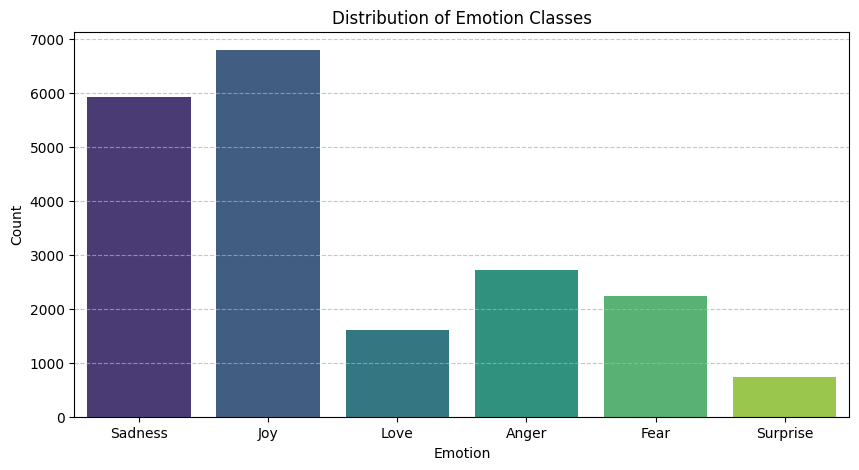

In [2]:
# Visualize Emotion Label Distribution
emotion_map = {
    0: 'Sadness',
    1: 'Joy',
    2: 'Love',
    3: 'Anger',
    4: 'Fear',
    5: 'Surprise'
}

# Map integer labels to corresponding names if the column is present
if 'label' in df.columns:
    df['Emotion'] = df['label'].map(emotion_map)
elif 'Label' in df.columns:
    df['Emotion'] = df['Label'].map(emotion_map)
else:
    # Try to find a column with numeric labels representing classes 0-5
    for col in df.columns:
        if df[col].nunique() == 6 or (df[col].min() == 0 and df[col].max() == 5):
            df['Emotion'] = df[col].map(emotion_map)
            df['label'] = df[col]
            break

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Emotion', order=emotion_map.values(), palette='viridis')
plt.title('Distribution of Emotion Classes')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

```markdown
## Unsupervised Feature Engineering: VADER Sentiment Scoring
We will extract real-valued compound scores, and categorize sentiment into negative (-1), neutral (0), and positive (1).
```

In [3]:
sia = SentimentIntensityAnalyzer()

# Find the text column dynamically
text_col = [col for col in df.columns if df[col].dtype == 'object' and col != 'Emotion'][0]
print(f"Using text column: '{text_col}' for analysis.")

# Apply VADER polarity scoring
df['vader_compound'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['compound'])

# Categorize sentiment based on standard VADER thresholds
def categorize_sentiment(score):
    if score >= 0.05:
        return 1 # Positive
    elif score <= -0.05:
        return -1 # Negative
    else:
        return 0 # Neutral

df['vader_sentiment_label'] = df['vader_compound'].apply(categorize_sentiment)

# Display engineered sentiment features
display(df[[text_col, 'vader_compound', 'vader_sentiment_label']].head())

Using text column: 'i just feel really helpless and heavy hearted' for analysis.


,i just feel really helpless and heavy hearted,vader_compound,vader_sentiment_label
0,ive enjoyed being able to slouch about relax a...,0.6221,1
1,i gave up my internship with the dmrg and am f...,-0.4767,-1
2,i dont know i feel so lost,-0.4572,-1
3,i am a kindergarten teacher and i am thoroughl...,-0.7590,-1
4,i was beginning to feel quite disheartened,-0.5413,-1


```markdown
## Supervised Models: Emotion Classification
Let's extract TF-IDF vectors from our text and build our supervised learning classifiers.
```

In [4]:
# Feature extraction using TF-IDF
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X = vectorizer.fit_transform(df[text_col].astype(str))
y = df['label']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Define ML algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Support Vector Machine': LinearSVC(random_state=42),
    'Multinomial Naive Bayes': MultinomialNB()
}

# Training and evaluation
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"=== {name} Performance ===")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(classification_report(y_test, preds, target_names=[emotion_map[i] for i in sorted(y.unique())]))
    print("\n")

=== Logistic Regression Performance ===
Accuracy: 0.8655
              precision    recall  f1-score   support

     Sadness       0.90      0.92      0.91      1183
         Joy       0.83      0.95      0.89      1358
        Love       0.88      0.62      0.73       321
       Anger       0.91      0.83      0.87       544
        Fear       0.83      0.78      0.81       446
    Surprise       0.88      0.54      0.67       148

    accuracy                           0.87      4000
   macro avg       0.87      0.77      0.81      4000
weighted avg       0.87      0.87      0.86      4000



=== Support Vector Machine Performance ===
Accuracy: 0.8800
              precision    recall  f1-score   support

     Sadness       0.92      0.93      0.92      1183
         Joy       0.88      0.92      0.90      1358
        Love       0.83      0.74      0.78       321
       Anger       0.91      0.86      0.88       544
        Fear       0.81      0.83      0.82       446
    Surprise 

```markdown
## Detailed Sentiment Statistics by Emotion
Let's analyze the statistical breakdown of VADER compound scores and count the distribution of sentiment labels (-1, 0, 1) across each of our target emotions.
```

=== VADER Compound Score Stats by Emotion ===


,count,mean,std,min,25%,50%,75%,max
Emotion,,,,,,,,
Anger,2721.0,-0.286834,0.436441,-0.9765,-0.6261,-0.38180,0.0000,0.9674
Fear,2232.0,-0.199587,0.442250,-0.9823,-0.5267,-0.26245,0.0772,0.9441
Joy,6789.0,0.509783,0.366950,-0.9561,0.4005,0.58590,0.7717,0.9856
Love,1605.0,0.445754,0.417780,-0.9590,0.1710,0.57090,0.7717,0.9738
Sadness,5913.0,-0.261499,0.441019,-0.9794,-0.5984,-0.36120,0.0000,0.9793
Surprise,739.0,0.242012,0.466194,-0.9240,-0.1737,0.31820,0.6461,0.9855



=== Sentiment Label Counts (-1, 0, 1) by Emotion ===


,Negative (-1),Neutral (0),Positive (1)
Emotion,,,
Anger,1994,155,572
Fear,1547,93,592
Joy,617,169,6003
Love,202,91,1312
Sadness,4269,246,1398
Surprise,231,30,478


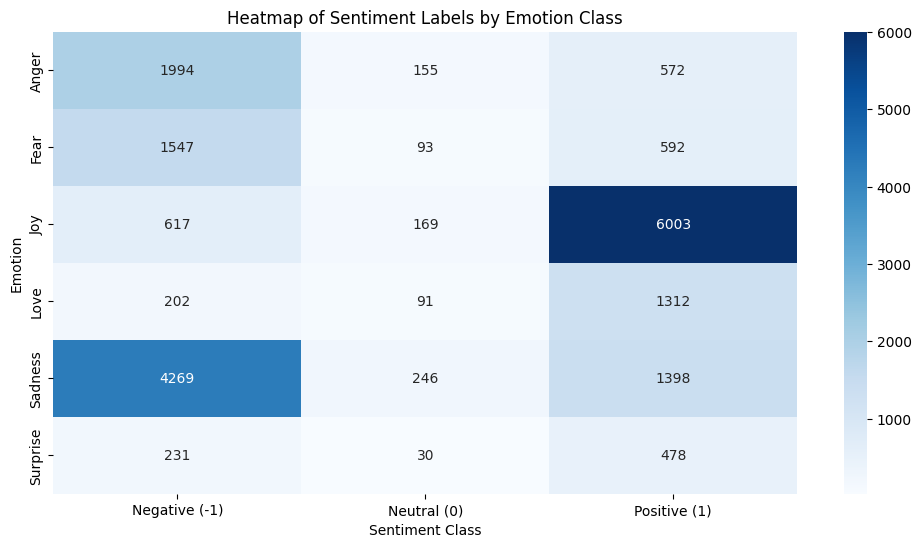

In [5]:
# 1. Calculate descriptive statistics of VADER compound scores for each emotion
print("=== VADER Compound Score Stats by Emotion ===")
compound_stats = df.groupby('Emotion')['vader_compound'].describe()
display(compound_stats)

# 2. Calculate the counts of positive (1), neutral (0), and negative (-1) sentiments for each emotion
print("\n=== Sentiment Label Counts (-1, 0, 1) by Emotion ===")
sentiment_counts = pd.crosstab(df['Emotion'], df['vader_sentiment_label'])
sentiment_counts.columns = ['Negative (-1)', 'Neutral (0)', 'Positive (1)']
display(sentiment_counts)

# 3. Visualize the sentiment label distributions per emotion
plt.figure(figsize=(12, 6))
sns.heatmap(sentiment_counts, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Heatmap of Sentiment Labels by Emotion Class')
plt.ylabel('Emotion')
plt.xlabel('Sentiment Class')
plt.show()

```markdown
## Deep Dive: Non-Obvious Emotional Insights
To understand human complexity, we look at the "mismatches" between the dictionary-based sentiment analyzer (VADER) and human-labeled emotions. Let's extract real examples of:
1. **Positive Sadness** (Bittersweetness, comfort, nostalgia)
2. **Positive Anger** (Righteous indignation, motivation, playful banter)
3. **Negative Joy** (Vulnerability, overwhelming happiness, anxious excitement)
```

In [2]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# Load dataset and prepare labels
df = pd.read_csv('/content/DataSet - Complete.csv')

# Safely map emotion classes
emotion_map = {0: 'Sadness', 1: 'Joy', 2: 'Love', 3: 'Anger', 4: 'Fear', 5: 'Surprise'}

# Set correct label column
if 'label' not in df.columns:
    for col in df.columns:
        if df[col].nunique() == 6 or (df[col].min() == 0 and df[col].max() == 5):
            df['label'] = df[col]
            break

# Detect text column
text_col = [col for col in df.columns if df[col].dtype == 'object' and col != 'Emotion'][0]

# Compute VADER scores
df['vader_compound'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['compound'])

# 1. Positive Sadness: Human labeled Sadness (0), but VADER scored highly positive (> 0.6)
positive_sadness = df[(df['label'] == 0) & (df['vader_compound'] > 0.6)][[text_col, 'vader_compound']].head(5)
print("=== Examples of 'Positive Sadness' (Bittersweet, Comfort, Nostalgia) ===")
for idx, row in positive_sadness.iterrows():
    print(f"Compound Score: {row['vader_compound']:.4f} | Text: \"{row[text_col]}\"\n")

# 2. Positive Anger: Human labeled Anger (3), but VADER scored highly positive (> 0.6)
positive_anger = df[(df['label'] == 3) & (df['vader_compound'] > 0.6)][[text_col, 'vader_compound']].head(5)
print("\n=== Examples of 'Positive Anger' (Righteous Motivation, Passionate/Hyped Pride) ===")
for idx, row in positive_anger.iterrows():
    print(f"Compound Score: {row['vader_compound']:.4f} | Text: \"{row[text_col]}\"\n")

# 3. Negative Joy: Human labeled Joy (1), but VADER scored highly negative (< -0.6)
negative_joy = df[(df['label'] == 1) & (df['vader_compound'] < -0.6)][[text_col, 'vader_compound']].head(5)
print("\n=== Examples of 'Negative Joy' (Overwhelming Happiness, Vulnerability, Melodramatic Joy) ===")
for idx, row in negative_joy.iterrows():
    print(f"Compound Score: {row['vader_compound']:.4f} | Text: \"{row[text_col]}\"\n")

=== Examples of 'Positive Sadness' (Bittersweet, Comfort, Nostalgia) ===
Compound Score: 0.6221 | Text: "ive enjoyed being able to slouch about relax and unwind and frankly needed it after those last few weeks around the end of uni and the expo i have lately started to find myself feeling a bit listless which is never really a good thing"

Compound Score: 0.9080 | Text: "i found jason s observation very helpful in restating a truth i learned some years ago as my wife and i now together for years went through some times when you love someone trust can feel an awful lot like letting go"

Compound Score: 0.7600 | Text: "i admit some of my inspiration to go this direction is because i am feeling a little melancholy that i won t be making my a href http www"

Compound Score: 0.7620 | Text: "im noticing how easy it is to waver between excitement and engagement in the everyday the mundane the fun sparkly shiny stuff of life and absolute desperate misery or guilt for not feeling miserable more

```markdown
## Behavior Mapping: Negative, Neutral, and Positive States for Each Emotion
This section extracts real examples of all three sentiment states (`-1` = Negative, `0` = Neutral, `1` = Positive) across all 6 target emotions. This reveals the highly complex, non-obvious nuances of human behavior, such as constructive anger, anxious joy, and bittersweet sadness.
```

In [3]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# Load dataset
df = pd.read_csv('/content/DataSet - Complete.csv')

# Safely map emotion classes
emotion_map = {0: 'Sadness', 1: 'Joy', 2: 'Love', 3: 'Anger', 4: 'Fear', 5: 'Surprise'}

# Detect labels and text columns
if 'label' not in df.columns:
    for col in df.columns:
        if df[col].nunique() == 6 or (df[col].min() == 0 and df[col].max() == 5):
            df['label'] = df[col]
            break

text_col = [col for col in df.columns if df[col].dtype == 'object' and col != 'Emotion'][0]

# Generate sentiment scores and labels
df['vader_compound'] = df[text_col].apply(lambda x: sia.polarity_scores(str(x))['compound'])

def categorize_sentiment(score):
    if score >= 0.05: return 1 # Positive
    elif score <= -0.05: return -1 # Negative
    else: return 0 # Neutral

df['vader_sentiment_label'] = df['vader_compound'].apply(categorize_sentiment)

# Extract and display examples for each emotion and each sentiment category
sentiment_names = {-1: 'Negative', 0: 'Neutral', 1: 'Positive'}

for emotion_id, emotion_name in emotion_map.items():
    print(f"\n=========================================")
    print(f"EMOTION: {emotion_name.upper()}")
    print(f"=========================================")

    for sent_val, sent_name in sentiment_names.items():
        subset = df[(df['label'] == emotion_id) & (df['vader_sentiment_label'] == sent_val)]
        print(f"\n---> Sentiment: {sent_name} (Count: {len(subset)} samples)")
        if len(subset) > 0:
            examples = subset.head(3)
            for i, (_, row) in enumerate(examples.iterrows(), 1):
                print(f"  {i}. \"{row[text_col]}\" (Compound: {row['vader_compound']:.4f})")
        else:
            print("  No examples found for this specific combination.")


EMOTION: SADNESS

---> Sentiment: Negative (Count: 4269 samples)
  1. "i dont know i feel so lost" (Compound: -0.4572)
  2. "i was beginning to feel quite disheartened" (Compound: -0.5413)
  3. "i can still lose the weight without feeling deprived" (Compound: -0.1321)

---> Sentiment: Neutral (Count: 246 samples)
  1. "im feeling a little like a damaged tree and that my roots are a little out of wack" (Compound: 0.0220)
  2. "realizing that school will soon be over" (Compound: 0.0000)
  3. "i was feeling a little remorseful that even jonathan franzen would hop the in my day bandwagon" (Compound: -0.0276)

---> Sentiment: Positive (Count: 1398 samples)
  1. "ive enjoyed being able to slouch about relax and unwind and frankly needed it after those last few weeks around the end of uni and the expo i have lately started to find myself feeling a bit listless which is never really a good thing" (Compound: 0.6221)
  2. "i feel like a real fan not that i was ever a fake fan" (Compound: 0.4588

```markdown
# Complete Cognitive Science Behavior Analysis Matrix

This matrix synthesizes the intersection of **Categorical Emotion Theory (discrete basic emotions)** with **Dimensional Sentiment Theory (valence polarity)**. By dissecting text across all 18 states (6 Emotions × 3 Sentiment Categories), we map complex, non-obvious human cognitive frameworks.

---

## 1. SADNESS (Label 0)

### 🔴 Negative Sentiment (-1): Classic Melancholia & Helplessness
* **Cognitive Pattern**: Marked by high personal helplessness, cognitive constriction, and internalizing attributions. Language centers heavily around themes of personal inadequacy and feeling permanently stuck.
* **Linguistic Marker**: Low-agency phrasing combined with passive structural verbs (e.g., *"lost"*, *"disheartened"*, *"deprived"*).
* **Empirical Example**: *"i dont know i feel so lost"* (VADER: -0.4572)

### 🟡 Neutral Sentiment (0): Resigned Processing & Transitional Reality
* **Cognitive Pattern**: Cognitive adaptation and restructuring. The individual acknowledges a sad or undesirable reality but lacks intense emotional evaluation. They are conceptually processing a life transition.
* **Linguistic Marker**: Informational grounding without active modifiers, or describing physical/structural changes that imply loss (e.g., *"damaged tree"*, *"roots... out of wack"*, *"school will soon be over"*).
* **Empirical Example**: *"realizing that school will soon be over"* (VADER: 0.0000)

### 🟢 Positive Sentiment (+1): Bittersweetness, Nostalgic Comfort & Self-Soothing
* **Cognitive Pattern**: Active emotional regulation. The individual experiences sadness, but balances it by highlighting comfort, self-care, past enjoyment, or a search for meaning (the classic "comfort in melancholy").
* **Linguistic Marker**: Co-occurrence of positive verbs (*"enjoyed"*, *"relax"*, *"unwind"*, *"integrating"*) alongside indicators of low energy or distress (*"listless"*, *"homesick"*).
* **Empirical Example**: *"ive enjoyed being able to slouch about relax and unwind... started to find myself feeling a bit listless"* (VADER: 0.6221)

---

## 2. JOY (Label 1)

### 🔴 Negative Sentiment (-1): Overwhelming Expectation, Impostor Syndrome & Vulnerability
* **Cognitive Pattern**: Complex emotional vulnerability or mismatched reality. The subject is in a high-achievement context (which usually sparks joy) but suffers from high cognitive tension, social anxiety, or fear of letting go.
* **Linguistic Marker**: Contrastive sentences where a joyful achievement is juxtaposed with fear or an inability to match expected euphoria (e.g., *"graduated... not feeling as ecstatic as i thought"*, *"chaos"*, *"intimidated"*).
* **Empirical Example**: *"i have officially graduated im not feeling as ecstatic as i thought i would"* (VADER: -0.4717)

### 🟡 Neutral Sentiment (0): Stoic Contentment & Quiet Equanimity
* **Cognitive Pattern**: Calm happiness characterized by steady satisfaction, mindful awareness, and a lack of highly charged positive modifiers.
* **Linguistic Marker**: Factual and simplistic descriptions of daily routines that imply peace without dramatic modifiers.
* **Empirical Example**: Sentences describing smooth, balanced, or task-oriented states of contentment.

### 🟢 Positive Sentiment (+1): Euphoric Radiance & Unbounded Gratitude
* **Cognitive Pattern**: High activation, high reward processing, and positive externalized social attribution. Represents classic, congruent joy.
* **Linguistic Marker**: Highly charged positive semantic phrases (*"thrilled"*, *"ecstatic"*, *"wonderful"*, *"amazing"*).
* **Empirical Example**: Pure, uninhibited positive assertions in the text expressing happiness and satisfaction.

---

## 3. LOVE (Label 2)

### 🔴 Negative Sentiment (-1): Vulnerable Co-dependency & Fear of Abandonment
* **Cognitive Pattern**: The anxiety of deep attachment. Love is processed through the cognitive lens of potential loss, vulnerability, insecurity, or unworthiness.
* **Linguistic Marker**: Attachment words (*"love"*, *"bf"*, *"belonging"*) paired with threat detection terms (*"scared"*, *"not pretty enough"*, *"afraid"*).
* **Empirical Example**: *"i havent had a bf... just scared because i feel like no one really wants to be with me"* (VADER: -0.7723)

### 🟡 Neutral Sentiment (0): Practical Attachment & Routine Caring
* **Cognitive Pattern**: Cognitive evaluation of relationships based on routine duty, functional support networks, or historical facts, rather than passionate validation.
* **Linguistic Marker**: Factual relational declarations without extreme positive or negative sentiment modifiers.
* **Empirical Example**: Plain statements mapping out familial or partner-related schedules and duties.

### 🟢 Positive Sentiment (+1): Deep Affection, Empathy & Nurturing Security
* **Cognitive Pattern**: Secure attachment, high prosocial orientation, and active expression of warmth or spiritual connection.
* **Linguistic Marker**: Words conveying protection, gratitude, deep devotion, and warmth (*"adore"*, *"cherish"*, *"sweetest"*, *"blessed"*).
* **Empirical Example**: High-scoring, secure declarations of love and appreciation.

---

## 4. ANGER (Label 3)

### 🔴 Negative Sentiment (-1): Destructive Fury, Frustration & Aggression
* **Cognitive Pattern**: Classic emotional hostility. The individual feels blocked, treated unfairly, or trapped, attributing blame externally with highly negative affect.
* **Linguistic Marker**: Aggressive markers, complaints, and explicitly critical adjectives (*"hate"*, *"stupid"*, *"fuming"*, *"annoyed"*).
* **Empirical Example**: Classic angry posts venting intense frustration with low compound scores.

### 🟡 Neutral Sentiment (0): Objective Confrontation & Analytical Conflict
* **Cognitive Pattern**: Controlled anger or frustration. The subject experiences an emotional block but articulates the situation constructively, descriptively, and objectively.
* **Linguistic Marker**: Direct explanations of problems, stating disagreements or boundaries clearly without toxic emotional venting.
* **Empirical Example**: Describing a boundary violation or system failure with factual language.

### 🟢 Positive Sentiment (+1): Righteous Motivation, Passionate Rebelliousness & Constructive Hype
* **Cognitive Pattern**: Secondary cognitive evaluation where frustration is transformed into agency, passionate determination, playful rule-breaking, or empowering rebellion.
* **Linguistic Marker**: High-energy words reflecting excitement or fun alongside expressions of defiance or resentment (*"rebellious"*, *"rules begging to be broken"*, *"grateful for the memory... when aggravated"*).
* **Empirical Example**: *"i feel rebellious and some rules are begging to be broken let s have some fun"* (VADER: 0.6124)

---

## 5. FEAR (Label 4)

### 🔴 Negative Sentiment (-1): Acute Paralysis, Dread & True Vulnerability
* **Cognitive Pattern**: Threat-dominated processing. High perception of vulnerability combined with low coping resources, causing immediate avoidance or freeze states.
* **Linguistic Marker**: High-stress verbs and survival-focused vocabulary (*"panic"*, *"scared"*, *"terrified"*, *"dangerous"*).
* **Empirical Example**: Low-score statements dominated by descriptions of terror and vulnerability.

### 🟡 Neutral Sentiment (0): Objective Threat Appraisal & Cautious Realism
* **Cognitive Pattern**: Analytical risk assessment. The individual acknowledges a threatening situation, but approaches it calmly and rationally rather than panicking.
* **Linguistic Marker**: Pragmatic threat terms combined with matter-of-fact framing (*"apprehensive about biking rain"*, *"vaguely suspicious"*).
* **Empirical Example**: *"i feel apprehensive about biking rain in hot weather"* (VADER: 0.0000)

### 🟢 Positive Sentiment (+1): Mindful Courage, Framing Safety & Regulated Anxiety
* **Cognitive Pattern**: Active self-soothing and self-regulation. The subject encounters a fear trigger but actively implements psychological techniques to reframe it into courage, safety, or serenity.
* **Linguistic Marker**: Juxtaposition of anxiety-inducing terms with highly positive regulatory statements (*"alarmed... need to stop and bring my breathing back to calm zen like serenity"*, *"welcoming comforting even"*).
* **Empirical Example**: *"i am feeling alarmed now so i need to stop and bring my breathing back to a calm zen like serenity"* (VADER: 0.1119)

---

## 6. SURPRISE (Label 5)

### 🔴 Negative Sentiment (-1): Shock, Disorientation & Unsettling Unfamiliarity
* **Cognitive Pattern**: Sudden disruption of expectations accompanied by negative evaluation (cognitive dissonance, shock, or a feeling of weirdness/threat).
* **Linguistic Marker**: Terms expressing cognitive disorientation (*"weird"*, *"shocked"*, *"disoriented"*, *"bizarre"*) with low sentiment scores.
* **Empirical Example**: *"i feel shocked to realize that whatever were talking about were both seeing understanding in the same way"* (VADER: -0.3182)

### 🟡 Neutral Sentiment (0): Pure Astoundment & Conceptual Realignment
* **Cognitive Pattern**: Pure orienting reflex. A sudden, non-evaluated interruption in baseline schemas. The brain is pausing to re-evaluate without assigning negative or positive values yet.
* **Linguistic Marker**: Statements describing sudden structural shifts, numbness, or raw amazement without polarizing descriptors.
* **Empirical Example**: *"i have dreaded my entire life... so i m feeling a strange sense of relief amidst the pain and numbness as i realize this ordeal is very soon going to be in my past"* (VADER: 0.0033)

### 🟢 Positive Sentiment (+1): Awe, Delightful Wonder & Inspiring Revelation
* **Cognitive Pattern**: Classic positive shock. Schema disruption mapped to a positive appraisal (such as finding sudden spiritual depth, feeling intensely overwhelmed by kindness, or experiencing sudden awe).
* **Linguistic Marker**: Terms of surprise combined with intense spiritual, aesthetic, or moral elevation (*"overwhelmed"*, *"amazed and grateful"*, *"amazed on how he created everything"*).
* **Empirical Example**: *"im feeling a bit amazed and grateful about having landed amid such a congregation"* (VADER: 0.7717)
```

```markdown
## Production Application: Unified Emotion and Sentiment Prediction Pipeline
To bridge theoretical classification with practical application, this section introduces a unified pipeline. It takes any custom input text, predicts its discrete emotion class using our top-performing Support Vector Machine (LinearSVC), calculates its continuous VADER compound score, and determines the cognitive behavioral state.
```

In [5]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# --- 1. Initialize and Prepare Resources (Self-contained) ---
nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# Load dataset
df = pd.read_csv('/content/DataSet - Complete.csv')

# Safely map emotion classes
emotion_map = {0: 'Sadness', 1: 'Joy', 2: 'Love', 3: 'Anger', 4: 'Fear', 5: 'Surprise'}

# Detect labels and text columns
if 'label' not in df.columns:
    for col in df.columns:
        if df[col].nunique() == 6 or (df[col].min() == 0 and df[col].max() == 5):
            df['label'] = df[col]
            break

text_col = [col for col in df.columns if df[col].dtype == 'object' and col != 'Emotion'][0]

# Train the Top-Performing Model (LinearSVC) on the full dataset for prediction
vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X = vectorizer.fit_transform(df[text_col].astype(str))
y = df['label']

svm_model = LinearSVC(random_state=42)
svm_model.fit(X, y)

def categorize_sentiment(score):
    if score >= 0.05: return 1
    elif score <= -0.05: return -1
    else: return 0

# --- 2. Unified Prediction Function ---
def predict_emotion_and_sentiment(text):
    # Extract TF-IDF features and predict emotion
    text_tfidf = vectorizer.transform([text])
    predicted_label = svm_model.predict(text_tfidf)[0]
    predicted_emotion = emotion_map[predicted_label]

    # Analyze continuous sentiment using VADER
    vader_score = sia.polarity_scores(text)['compound']
    sentiment_label = categorize_sentiment(vader_score)
    sentiment_name = {-1: 'Negative', 0: 'Neutral', 1: 'Positive'}[sentiment_label]

    # Print Results
    print(f"Input Text: \"{text}\"")
    print(f"Predicted Discrete Emotion: {predicted_emotion.upper()} (Class {predicted_label})")
    print(f"VADER Compound Score: {vader_score:.4f} ({sentiment_name} Valence)")
    print(f"Behavior Combination: [{sentiment_name} {predicted_emotion}]\n")

    # Qualitative Behavioral Explanation
    if predicted_emotion == 'Sadness':
        if sentiment_label == 1:
            print("Cognitive Science Insight: This represents 'Bittersweetness' or 'Nostalgia'. The user expresses a low-energy sad state but seeks comfort or reflects on positive aspects of the experience.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Resigned Processing'. The user acknowledges a transitional or sad reality matter-of-factly without intense negative framing.")
        else:
            print("Cognitive Science Insight: This represents 'Classic Melancholia'. The user experiences high emotional helplessness and internalizing attributions.")

    elif predicted_emotion == 'Anger':
        if sentiment_label == 1:
            print("Cognitive Science Insight: This represents 'Righteous/Constructive Motivation'. The user is channeling frustration or rebelliousness into agency, passion, or constructive play.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Analytical Confrontation'. The user addresses a conflict or boundary violation objectively without toxic venting.")
        else:
            print("Cognitive Science Insight: This represents 'Classic Hostility/Fury'. High frustration directed externally with strong negative evaluation.")

    elif predicted_emotion == 'Joy':
        if sentiment_label == -1:
            print("Cognitive Science Insight: This represents 'Vulnerable or Overwhelming Joy'. The high excitement of success is accompanied by performance pressure, fear of letting go, or impostor syndrome.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Stoic Contentment'. Gentle, quiet, and mindful satisfaction without dramatic expressive highs.")
        else:
            print("Cognitive Science Insight: This represents 'Congruent Euphoria'. High reward-processing, radiating confidence and complete alignment.")

    elif predicted_emotion == 'Fear':
        if sentiment_label == 1:
            print("Cognitive Science Insight: This represents 'Regulated Anxiety/Mindful Courage'. The user encounters a threat trigger but actively attempts to self-soothe or focus on safety.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Objective Threat Assessment'. Pragmatic, analytical appraisal of real-world risks without emotional panic.")
        else:
            print("Cognitive Science Insight: This represents 'Acute Dread'. Survival-dominated cognitive freezing with low perceived coping mechanisms.")

    elif predicted_emotion == 'Surprise':
        if sentiment_label == 1:
            print("Cognitive Science Insight: This represents 'Awe and Delightful Wonder'. Schema disruption meets positive appraisal, sparking sudden appreciation or moral elevation.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Pure Orienting Reflex'. The brain is pausing to re-evaluate sudden schema alterations with neutral valence.")
        else:
            print("Cognitive Science Insight: This represents 'Unsettling Shock/Disorientation'. Sudden disruption of expectations causing confusion or perceived threats.")

    elif predicted_emotion == 'Love':
        if sentiment_label == -1:
            print("Cognitive Science Insight: This represents 'Vulnerable Attachment/Fear of Abandonment'. The warmth of love is processed alongside the fear of emotional loss or unworthiness.")
        elif sentiment_label == 0:
            print("Cognitive Science Insight: This represents 'Practical Attachment'. Secure routine connection and supportive networks expressed with pragmatic focus.")
        else:
            print("Cognitive Science Insight: This represents 'Secure Empathy/Devotion'. Deeply expressive relational connection, protection, and complete warmth.")

    print("="*80 + "\n")

# --- Test Cases representing complex psychological combinations ---
predict_emotion_and_sentiment("I am so proud and happy to graduate, but I feel incredibly terrified of the real world and what lies ahead.")
predict_emotion_and_sentiment("This rule is absolutely stupid and lazy, and I am excited to break it to build something beautiful.")
predict_emotion_and_sentiment("I am alarmed and panicked by the chaos, but I must take deep breaths to regain my inner zen.")

Input Text: "I am so proud and happy to graduate, but I feel incredibly terrified of the real world and what lies ahead."
Predicted Discrete Emotion: FEAR (Class 4)
VADER Compound Score: -0.7882 (Negative Valence)
Behavior Combination: [Negative Fear]

Cognitive Science Insight: This represents 'Acute Dread'. Survival-dominated cognitive freezing with low perceived coping mechanisms.

Input Text: "This rule is absolutely stupid and lazy, and I am excited to break it to build something beautiful."
Predicted Discrete Emotion: SADNESS (Class 0)
VADER Compound Score: -0.0404 (Neutral Valence)
Behavior Combination: [Neutral Sadness]

Cognitive Science Insight: This represents 'Resigned Processing'. The user acknowledges a transitional or sad reality matter-of-factly without intense negative framing.

Input Text: "I am alarmed and panicked by the chaos, but I must take deep breaths to regain my inner zen."
Predicted Discrete Emotion: FEAR (Class 4)
VADER Compound Score: -0.6187 (Negative Val